# Measure how post-selection validation limits a planning claim

**Question:** How do empty schedules and checkpoint selection change what validation summaries mean?

**Level 2.** Method practice.

**Prerequisites:** Read the matching frontier-state and split-design lessons. **Estimated time:** 45 minutes.

## Objectives

This lesson reads the committed, path-sanitized summary of the five-member training run and all 200 rows from its validation-only replay. It verifies the split identity and source commit, recomputes completion, objective, and coverage summaries, inspects member checkpoint-selection histories, and plots case-level results beside their limits. The records preserve genuine outputs from the product pipeline without model weights or machine-specific paths. This is an evidence-processing lesson: it does not retrain the actor, recreate lost test outputs, or score any product case.

## Setup

Use the pinned NumPy and Matplotlib packages from the repository notebook environment. The records and frozen split manifest are committed under the learned-frontier design folder, so this lesson runs from a fresh clone without access to the original training disk. Do not replace a missing record with copied values or a later run. Its JSON schema, digest fields, and source commit are part of provenance. A failed integrity check is a stop condition because untracked substitutions would make the displayed result impossible to audit.

Environment install command:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Load committed provenance records and product split functions.
import hashlib
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256
from pipeline.model.frontier_policy import validate_split_manifest

RECORDS = ROOT / "docs/design/features/learned-frontier/records"
summary = json.loads((RECORDS / "training-summary.json").read_text(encoding="utf-8"))
diagnostic = json.loads((RECORDS / "validation-diagnostic.json").read_text(encoding="utf-8"))
manifest = json.loads(
    (ROOT / "docs/design/features/learned-frontier/split-manifest.json").read_text(encoding="utf-8")
)["manifest"]
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Data

The training summary omits checkpoint locations but retains the original receipt's digest, source commit, engine version, five member seeds, selected and final checkpoint hashes, transition histories, and compute caps. The validation diagnostic stores one row per declared validation seed, with graph family, size, assignment count, normalized objective, two coverage fractions, and independent validation status. A frozen manifest lists train, validation, and test partitions separately. None of the test rows appears in the validation record. The separate test and product-case results are outside this lesson and are processed in a dedicated analysis. These are generated records from the PhaseFlow pipeline, not MineLib observations; no external dataset is redistributed. The program code is MIT-licensed, not third-party data. Source: https://github.com/fsantibanezleal/CAOS_PhaseFlow. External checkpoints remain outside the repository.

## Method

First reconstruct the split from the product's generator and validate its disjointness. Match every diagnostic seed to the manifest's validation rows and verify the generator family, size, and independent-check status. Then recompute the descriptive aggregates from per-case rows instead of trusting the summary headline. For each training member, retain its validation history and selected checkpoint digest; a completed training receipt does not by itself establish a useful policy. The case plots retain empty schedules and zero coverage, while the distribution plot exposes the long tail. No threshold converts these validation observations into a test claim.

$$NPV(S)=\sum_{b\in S}\frac{v_b}{(1+\eta)^{p_b}},\qquad nNPV(S)=\frac{NPV(S)}{\max(\sum_{b\in B}|v_b|,10^{-12})}.$$

$$c^+=\frac{\sum_{b\in S}\max(v_b,0)}{\sum_{b\in B}\max(v_b,0)}.$$

Here $p_b$ is the assigned period, $\eta$ the discount rate, and $v_b$ the undiscounted block value. The $nNPV$ denominator is total absolute value, unlike the positive-value denominator in $c^+$. The implementation reports zero when a denominator is zero; that value has no denominator support and is not complete coverage.

Rebuild the frozen partitions and validate their disjointness.

In [2]:
# Validate split provenance, exact case membership, validator flags, and checkpoint history.
from pipeline.model.frontier_evidence import validate_frontier_diagnostic

audit = validate_frontier_diagnostic(manifest, summary, diagnostic)
print({key: value for key, value in audit.items() if key != "members"})


{'split_sha256': '18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c', 'source_commit': '4aa49f4e72b2563d652a5636f69c2c5a5582db00', 'validation_cases': 200, 'summary': {'cases': 200, 'nonempty_fraction': 0.49, 'mean_assigned_blocks': 1.84, 'mean_npv': 0.0014969291242116452, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0015200422109756784, 'maximum_npv': 0.052875241354758566}}


Join every diagnostic case to its frozen seed and size.

In [3]:
# Rebuild and inspect the frozen partitions; the evaluator used these declared groups.
case_ids = manifest["product_case_ids"]
rebuilt = build_split_manifest(case_ids)
print(
    {
        "train": len(rebuilt["train"]),
        "validation": len(rebuilt["validation"]),
        "test": len(rebuilt["test"]),
        "product_cases": len(case_ids),
    }
)
rows = diagnostic["case_results"]
expected = {row["seed"]: row for row in manifest["validation"]}
print(
    {
        "case_rows": len(rows),
        "validation_seeds": len(expected),
        "empty_schedules": sum(row["assigned_blocks"] == 0 for row in rows),
    }
)


{'train': 1000, 'validation': 200, 'test': 500, 'product_cases': 13}
{'case_rows': 200, 'validation_seeds': 200, 'empty_schedules': 102}


Recompute the reported distributions from the case rows.

In [4]:
# Apply the product analysis function without removing empty schedules.
from pipeline.model.frontier_evidence import summarize_case_rows

npv = np.asarray([row["normalized_npv"] for row in rows], dtype=float)
value_coverage = np.asarray([row["positive_value_coverage"] for row in rows], dtype=float)
assigned = np.asarray([row["assigned_blocks"] for row in rows], dtype=int)
computed = summarize_case_rows(rows)
assert np.isclose(computed["nonempty_fraction"], diagnostic["nonempty_schedule_fraction"])
assert np.isclose(computed["median_value_coverage"], diagnostic["median_positive_value_coverage"])
print(computed)


{'cases': 200, 'nonempty_fraction': 0.49, 'mean_assigned_blocks': 1.84, 'mean_npv': 0.0014969291242116452, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0015200422109756784, 'maximum_npv': 0.052875241354758566}


Inspect checkpoint-selection histories as training records.

In [5]:
# Inspect selected and final checkpoint records without conflating their roles.
member_rows = audit["members"]
print(member_rows)


[{'seed': 1103, 'transitions': 40960, 'stop': 'cpu-cap', 'selected_sha256': '4753af9ced29a9bc75f64b027529a4c0177d5928c9f4816a50631b33c4d06c63', 'final_sha256': '6182cd3ae52cad0015c7ed96d54a8f60e5cec0634daaea6bf4a3b8fb53c5ae6a', 'events': 1}, {'seed': 2207, 'transitions': 45056, 'stop': 'cpu-cap', 'selected_sha256': 'caf1600e8b8fdfd60c26afee124f177d7f381e9a4299119b2b7d0f82e68af31b', 'final_sha256': 'ec840cd652861af50ef9dc2532c0bc8dbbca0fa22d6d442315992c7740cf504f', 'events': 2}, {'seed': 3301, 'transitions': 61440, 'stop': 'cpu-cap', 'selected_sha256': 'b6df99794298e5420f221ee57511a6a2f231781ab1e94297258cca2f35ebcb2e', 'final_sha256': 'e987180fc606db217b1253e95d5af6e14e8ca1defbe76a630573d71fa8e2dfb0', 'events': 2}, {'seed': 4409, 'transitions': 53248, 'stop': 'cpu-cap', 'selected_sha256': '61acc411a5e651f40416383e32852fef899230c71d6ab2e901da4690bee1b03b', 'final_sha256': 'e7934164d72cbd68b29679e1d2af82242e3c832fe7bd8e36b84a452ff948f652', 'events': 2}, {'seed': 5519, 'transitions': 53248

Regenerate one validation graph from its frozen seed; this checks its public input contract only.

In [6]:
# Regenerate one validation graph from its frozen seed; this checks its public input contract only.
sample = rows[0]
example = generate_graph(sample["seed"], sample["family"], sample["size"])
print(
    {
        "seed": sample["seed"],
        "family": example.family,
        "size": len(example.instance.values),
        "features": FEATURE_NAMES,
    }
)


{'seed': 200000, 'family': 'crosscut', 'size': 32, 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


Fit a small normalizer on training graphs only and retain its digest with the feature order.

In [7]:
# Fit a small normalizer on training graphs only and retain its digest with the feature order.
train_graphs = [generate_graph(row["seed"], row["family"], row["size"]) for row in manifest["train"][:8]]
train_matrix = np.vstack([graph.node_features for graph in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
print({"training_rows": normalizer.train_rows, "normalizer_sha256": normalizer.sha256})


{'training_rows': 368, 'normalizer_sha256': 'd4aab3f7fd25827c85fe0841c36bff0e7a2c4a6bda2a3ae82407d61828ba247d'}


Inspect an empty decision state without scoring the saved validation outcomes.

In [8]:
# Inspect an empty decision state without scoring the saved validation outcomes.
ready = precedence_frontier(example.instance, (), 0)
feasible = feasible_frontier(example.instance, (), 0)
print({"ready": len(ready), "feasible": len(feasible), "subset": set(feasible).issubset(ready)})


{'ready': 1, 'feasible': 1, 'subset': True}


Run a transparent mechanics replay and validate it independently; this is not a validation-record result.

In [9]:
# Run a transparent mechanics replay and validate it independently; this is not a validation-record result.
score = lambda block, period, assigned: float(example.instance.values[block]) if block >= 0 else -1.0
mechanics_result = replay_frontier_policy(example.instance, score, tonnage=example.tonnage)
print(
    {
        "assignments": len(mechanics_result.assignments),
        "validated_npv": validate_schedule(example.instance, mechanics_result.assignments),
    }
)


{'assignments': 2, 'validated_npv': 0.9884496550171686}


### Comparison

The saved training history and the later validation replay answer different questions. Validation events selected checkpoints, so inspecting those values is part of model selection. The post-selection replay checks surviving policies against the same validation partition and its independent schedule validator. Agreement between the two views is useful for debugging but does not create an independent sample. The original one-shot synthetic test remains consumed and excluded. A later disjoint 500-seed test and the thirteen registered product-case outcomes are documented in a separate worked analysis; this lesson deliberately stays on training and post-selection validation. We therefore compare model-selection records here, not held-out policy performance.

### Evidence

The first figure plots every validation case and keeps zero-assignment plans visible. The second summarizes the fraction with at least one assignment and the positive-value coverage distribution on the reused split. A validator pass means each returned assignment satisfies the declared constraints; it does not mean the schedule is operationally complete. The difference between mean and median, alongside empty-plan frequency, diagnoses how a few nonempty outcomes affect an aggregate. Because checkpoints were selected on these same cases, these statistics remain descriptive and post-selection. They cannot justify superiority, generalization, or a user-facing schedule selector.

The record deliberately retains each seed and graph size rather than distributing only an aggregate table. This permits a reader to audit joins, reproduce quantiles, inspect outliers, and detect a missing row without guessing how the summary was made. Hashes bind the public summary to its external original receipt and frozen split. The public diagnostic is therefore sufficient for its stated descriptive calculations, while the private checkpoint files remain unnecessary for reproducing those calculations.

The summary intentionally does not include the state-action trajectories or trained weights. A reader can verify record membership, recalculate the published descriptive values, and inspect case variation, but cannot reconstruct the policy's choices from this compact record alone. That distinction is important for reproducibility: the lesson reproduces the analysis of the surviving record, not a lost evaluation. The split ledger also makes clear that replaying validation again would repeat model-selection data rather than create fresh evidence.

Plot every validation case, including empty schedules.

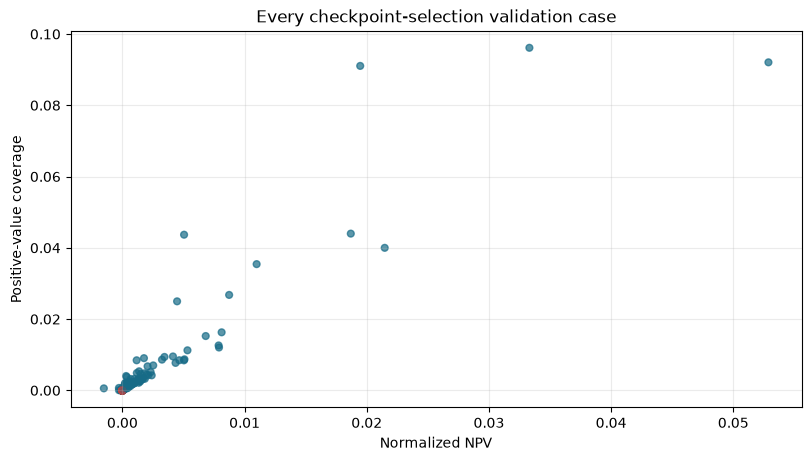

In [10]:
# Plot every case and identify zero-coverage outcomes directly.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.scatter(npv, value_coverage, c=np.where(assigned > 0, "#176B87", "#B84444"), alpha=0.7, s=24)
ax.set(
    xlabel="Normalized NPV",
    ylabel="Positive-value coverage",
    title="Every checkpoint-selection validation case",
)
ax.grid(alpha=0.25)
plt.show()


The plotted points are the original per-case rows. Their visible spread matters because a central statistic hides empty schedules and negative outcomes. Red points mark cases with no assigned block, while the vertical position retains positive-value coverage. This joint view exposes where a feasible schedule still leaves value untouched.

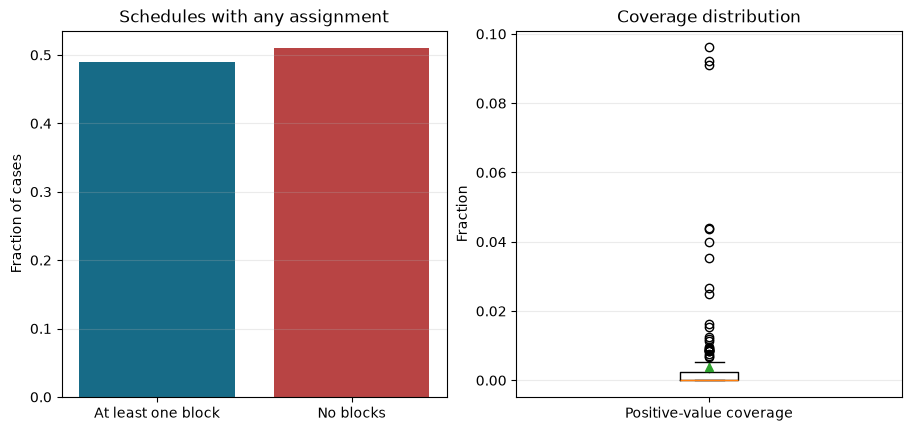

In [11]:
# Plot nonempty cases and coverage without calling nonemptiness completion.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
axes[0].bar(
    ["At least one block", "No blocks"],
    [np.mean(assigned > 0), np.mean(assigned == 0)],
    color=["#176B87", "#B84444"],
)
axes[0].set(ylabel="Fraction of cases", title="Schedules with any assignment")
axes[1].boxplot([value_coverage], tick_labels=["Positive-value coverage"], showmeans=True)
axes[1].set(ylabel="Fraction", title="Coverage distribution")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()


The bars compare the share of schedules with any assignment against empty schedules; they do not measure completeness. The boxplot summarizes positive-value coverage over every case, including zeros. Read both views with the scatterplot: a valid but short schedule can satisfy the constraints while leaving most positive value unassigned.

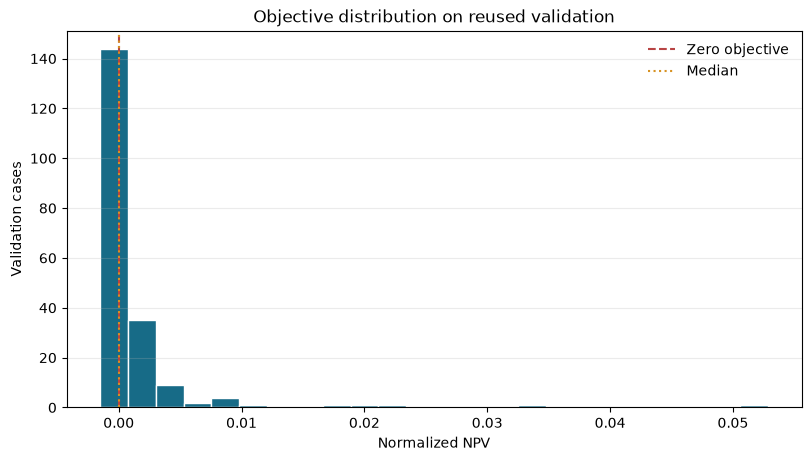

In [12]:
# Plot every normalized objective with median and zero references.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(npv, bins=24, color="#176B87", edgecolor="white")
ax.axvline(0, color="#B84444", linestyle="--", label="Zero objective")
ax.axvline(np.median(npv), color="#D79222", linestyle=":", label="Median")
ax.set(
    xlabel="Normalized NPV", ylabel="Validation cases", title="Objective distribution on reused validation"
)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()


The histogram retains every one of the 200 validation objectives, including negative values and zeros. The vertical guides mark zero and the sample median. Its shape describes these saved checkpoint-selection cases only: the partition was reused after checkpoint selection, so this plot is diagnostic and cannot support a held-out performance claim.

An inclusion-rule sensitivity check shows how summaries change when empty or very short schedules are omitted. These thresholds are diagnostic only; choosing one after seeing these values would be post-selection and cannot improve the evidence.

In [13]:
# Compare the full set with explicit minimum-assignment filters.
minimum_blocks = np.array([0, 1, 2, 4])
sensitivity = []
for threshold in minimum_blocks:
    keep = assigned >= threshold
    sensitivity.append(
        {
            "minimum_blocks": int(threshold),
            "cases": int(keep.sum()),
            "median_npv": float(np.median(npv[keep])),
            "median_positive_value_coverage": float(np.median(value_coverage[keep])),
        }
    )
print(sensitivity)


[{'minimum_blocks': 0, 'cases': 200, 'median_npv': 0.0, 'median_positive_value_coverage': 0.0}, {'minimum_blocks': 1, 'cases': 98, 'median_npv': 0.0009512115794102501, 'median_positive_value_coverage': 0.002476791673288803}, {'minimum_blocks': 2, 'cases': 66, 'median_npv': 0.0012964481264350315, 'median_positive_value_coverage': 0.0030127325972625412}, {'minimum_blocks': 4, 'cases': 34, 'median_npv': 0.0022164088935069065, 'median_positive_value_coverage': 0.004793463546494387}]


The first output reports the retained denominator and medians for each threshold. The plot repeats both quantities so exclusion effects remain visible.

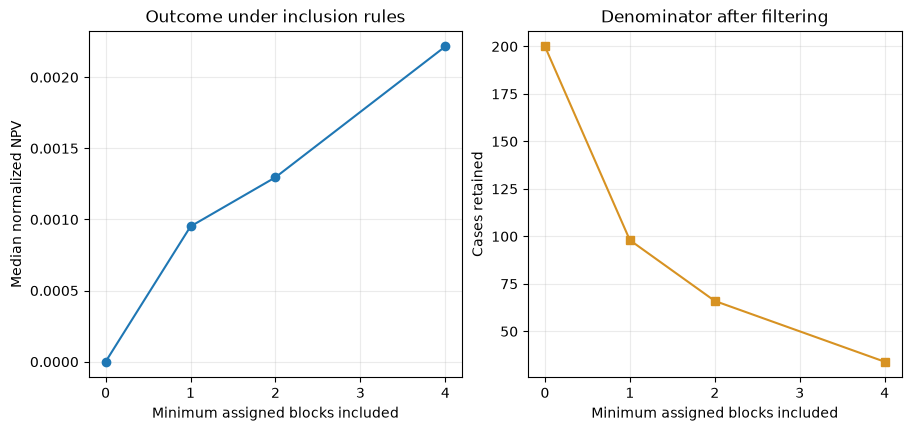

In [14]:
# Plot retained counts and medians for each inclusion threshold.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
axes[0].plot(minimum_blocks, [row["median_npv"] for row in sensitivity], marker="o")
axes[0].set(
    xlabel="Minimum assigned blocks included",
    ylabel="Median normalized NPV",
    title="Outcome under inclusion rules",
)
axes[1].plot(minimum_blocks, [row["cases"] for row in sensitivity], marker="s", color="#D79222")
axes[1].set(
    xlabel="Minimum assigned blocks included", ylabel="Cases retained", title="Denominator after filtering"
)
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


The printed row count is the denominator for each filtered statistic. Compare it with the all-case row before interpreting a median change: filtering removes zero and low-assignment outcomes and describes a selected subset, not a better policy. The sensitivity is conditional on these reused validation cases and is not an uncertainty interval.

## Results

Read the mean beside the median, range, nonempty fraction, assigned blocks, and both forms of coverage. A small positive mean can coexist with a median of zero when most runs return no value-bearing blocks and a few cases carry the aggregate. The member histories also show the finite training budget and actual validation checkpoints. Neither a saved checkpoint hash nor a finite loss curve is an acceptance criterion for a mining schedule. This training-validation lesson does not import or recompute held-out outcomes; those are analyzed separately from their own frozen receipts, never reconstructed from model behavior or replaced by validation rows.

**Answer:** Across 200 reused validation cases, 98 schedules are nonempty (0.49), mean assigned blocks are 1.84, and median normalized NPV and positive-value coverage are both 0. These are post-selection diagnostics, not held-out estimates.

## Summary

The record processing is reproducible and the negative evidence is preserved. These outputs support statements about capped training completion, checkpoint provenance, independently validated schedules on the reused validation set, and sparse coverage. They do not establish held-out performance. Consult the separate worked analysis for the disjoint test and product-case results, keeping its low coverage and failed inputs visible. Use this lesson to audit training and selection diagnostics; do not present validation as an independent benchmark or deployment evidence.

### Sensitivity and limits

Begin by checking whether the descriptive summary is driven by a small number of cases. Recompute medians, quartiles, minimum and maximum, nonempty fraction, and both coverage measures for each graph family and size. Plot the empirical distribution with zeros and negative values retained. A bootstrap over these 200 rows would quantify variation conditional on this reused validation sample; it would not remove checkpoint-selection bias or produce an independent test estimate. State the resampling unit and seed if such a diagnostic is added, and do not call it a confidence interval for future deposits.

The five training histories also need to be read as resource-bounded records. Compare each member's transition count, stop reason, validation cadence, selected checkpoint, and final checkpoint. A member that exhausts a CPU cap can still have a valid receipt, but completion alone says nothing about schedule usefulness. Missing or malformed history entries should fail the integrity check rather than be filled from another member. The case-level validator flag answers whether the stored assignment satisfies the implemented constraints; it does not certify the input assumptions or economic model. The current records contain no independent comparator, no untouched held-out outcomes, and no operationally sourced deposit data. Preserve those absences in every chart caption and summary.

Read every aggregate together with its denominator. A mean based on 200 rows is not meaningful if some rows were silently dropped, so reconcile case IDs against the frozen manifest before plotting. Check duplicate IDs, missing fields, non-finite values, and unexpected split membership. For category summaries, report counts as well as percentages because a small subgroup can otherwise look disproportionately persuasive. Keep plots descriptive and include the data-processing code alongside the source rows. If a later protocol introduces weighting or exclusions, version the rule, show unweighted results too, and preserve a record of which cases changed status. Do not tune a decision threshold on these reused observations and then describe the resulting score as an independent performance estimate. When a metric appears unusually favorable, trace it back to the exact per-case rows and confirm that its numerator and denominator use the same population. Preserve the original summary as a separate artifact when changing an analysis, then label the revised view with its code version and inputs. This permits readers to distinguish a faithful reproduction from a new exploratory calculation. Exploratory calculations can be useful for finding data defects, but once they influence a model choice they become part of model selection and must be disclosed in the next protocol.

### Use with your own data

The reusable `summarize_case_rows` function expects one dictionary per case with `seed`, `normalized_npv`, `positive_value_coverage`, and `assigned_blocks`; it rejects missing fields, non-finite metrics, and negative assignment counts. Load your JSON diagnostic's `case_results` list and call `summarize_case_rows(your_rows)`. Preserve zero-assignment rows in the full summary. For a sensitivity check only, filter with an explicit minimum-assignment threshold and print the retained count beside each statistic. These calculations describe your supplied rows; they do not validate a model or create an independent sample. For a new evaluation, also retain an opaque case ID, source-data digest, deposit family, size, split, configuration digest, checkpoint digest, validator status, and failures.

Choose a baseline before opening the test outcomes and run both methods on identical inputs and resource assumptions. Recompute objective and coverage from the canonical schedule and original case, then compare paired results using a predeclared analysis. Track missingness, warnings, exclusions, and code versions alongside metrics. Publish sufficient sanitized per-case data to reproduce every aggregate, while keeping restricted source data and weights under their access controls. Separate software validation, scientific evidence, operational acceptance, and release approval. This notebook demonstrates record processing only; your own data requires new provenance, protocol approval, and independent evaluation before any empirical claim.

Use the same row contract on another JSON diagnostic by changing this path. The complete list must retain empty schedules; the returned count is the denominator for every summary.

In [15]:
# Replace this repository path with your diagnostic JSON file.
your_path = RECORDS / "validation-diagnostic.json"
your_rows = json.loads(your_path.read_text(encoding="utf-8"))["case_results"]
print(summarize_case_rows(your_rows))


{'cases': 200, 'nonempty_fraction': 0.49, 'mean_assigned_blocks': 1.84, 'mean_npv': 0.0014969291242116452, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0015200422109756784, 'maximum_npv': 0.052875241354758566}


## References

The SDD and run records are maintained in the PhaseFlow repository. The clipped policy-gradient paper describes the optimizer family but does not support empirical claims for this mine-scheduling policy. All displayed counts, distributions, and summaries are recomputed from the committed JSON records.

- Policy-gradient method: https://arxiv.org/abs/1707.06347
- Adaptive optimizer: https://arxiv.org/abs/1412.6980
- Open-pit scheduling formulation: https://doi.org/10.1287/inte.2013.0731
- Implementation and records: https://github.com/fsantibanezleal/CAOS_PhaseFlow